In [11]:
import sys
import torch

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

assert torch.cuda.is_available(), "GPU is not available!"

device = torch.device("cuda:0")

print("GPU:", torch.cuda.get_device_name(0))
print("GPU Count:", torch.cuda.device_count())

x = torch.randn(1024, 1024, device=device)
y = x @ x

print("Tensor Device:", y.device)
print("GPU computation successful!")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
CUDA Available: True
GPU: Tesla T4
GPU Count: 2
Tensor Device: cuda:0
GPU computation successful!


In [3]:
!nvidia-smi

Wed Nov 25 06:38:00 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [4]:
import socket

print(socket.gethostbyname("github.com"))

140.82.121.3


In [5]:
import socket

for host in ["google.com", "github.com", "storage.googleapis.com"]:
    try:
        print(host, ":", socket.gethostbyname(host))
    except socket.gaierror as e:
        print(host, ":", e)

google.com : 172.253.153.102
github.com : 140.82.121.4
storage.googleapis.com : 74.125.128.207


In [6]:
!git clone https://github.com/TalhaSaleem-26/FloodVision-AI.git /kaggle/working/FloodVision-AI

Cloning into '/kaggle/working/FloodVision-AI'...
remote: Enumerating objects: 71, done.
remote: Counting objects: 100% (71/71), done.
remote: Compressing objects: 100% (62/62), done.
remote: Total 71 (delta 3), reused 71 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (71/71), 1.27 MiB | 24.60 MiB/s, done.
Resolving deltas: 100% (3/3), done.


In [7]:
%cd /kaggle/working/FloodVision-AI/ml

!ls -la

/kaggle/working/FloodVision-AI/ml
total 32
drwxr-xr-x 7 root root 4096 Nov 25 06:38 .
drwxr-xr-x 6 root root 4096 Nov 25 06:38 ..
drwxr-xr-x 2 root root 4096 Nov 25 06:38 configs
drwxr-xr-x 3 root root 4096 Nov 25 06:38 data
drwxr-xr-x 2 root root 4096 Nov 25 06:38 notebooks
-rw-r--r-- 1 root root  671 Nov 25 06:38 pyproject.toml
drwxr-xr-x 2 root root 4096 Nov 25 06:38 scripts
drwxr-xr-x 3 root root 4096 Nov 25 06:38 src


In [8]:
import importlib

packages = [
    "torch",
    "torchvision",
    "numpy",
    "pandas",
    "matplotlib",
    "seaborn",
    "rasterio",
    "cv2",
    "albumentations",
    "sklearn",
    "tqdm",
    "yaml",
    "google.cloud.storage"
]

for package in packages:
    try:
        module = importlib.import_module(package)
        version = getattr(module, "__version__", "")
        print(f"{package:25} OK {version}")
    except Exception as e:
        print(f"{package:25} FAILED: {e}")

torch                     OK 2.11.0+cu130
torchvision               OK 0.26.0+cu130
numpy                     OK 2.1.3
pandas                    OK 2.3.3
matplotlib                OK 3.10.0
seaborn                   OK 0.13.2
rasterio                  OK 1.5.2
cv2                       OK 4.14.0
albumentations            OK 2.0.8
sklearn                   OK 1.6.1
tqdm                      OK 4.67.3
yaml                      OK 6.0.3
google.cloud.storage      OK 3.17.1


In [9]:
!cat pyproject.toml

[build-system]
requires = ["setuptools>=68"]
build-backend = "setuptools.build_meta"

[project]
name = "floodvision"
version = "0.1.0"
description = "CNN-based satellite flood mapping and geospatial analysis"
requires-python = ">=3.11,<3.13"

dependencies = [
    "torch",
    "torchvision",
    "numpy",
    "pandas",
    "matplotlib",
    "seaborn",
    "rasterio",
    "opencv-python",
    "albumentations",
    "scikit-learn",
    "tqdm",
    "pyyaml",
    "google-cloud-storage"
]

[project.optional-dependencies]
dev = [
    "pytest",
    "jupyter",
    "ipykernel"
]

[tool.setuptools.packages.find]
where = ["src"]

[tool.pytest.ini_options]
testpaths = ["tests"]

In [10]:
!cat scripts/download_data.py

from pathlib import Path

import yaml
from google.cloud import storage
from tqdm import tqdm


# Project paths
BASE_DIR = Path(__file__).resolve().parents[1]
CONFIG_PATH = BASE_DIR / "configs" / "dataset.yaml"


def load_config():
    with open(CONFIG_PATH, "r", encoding="utf-8") as file:
        return yaml.safe_load(file)["dataset"]


def download_folder(client, bucket_name, prefix, destination, extension):
    destination.mkdir(parents=True, exist_ok=True)

    blobs = [
        blob
        for blob in client.list_blobs(bucket_name, prefix=prefix)
        if blob.name.endswith(extension)
    ]

    if not blobs:
        raise RuntimeError(f"No files found: {prefix}")

    print(f"\nFolder: {destination.name}")
    print(f"Total files: {len(blobs)}")

    for blob in tqdm(blobs, desc=destination.name):
        filename = Path(blob.name).name
        file_path = destination / filename

        # Skip previously downloaded files
        if file_path.exists() and file_path.stat().st_si

In [14]:
%cd /kaggle/working/FloodVision-AI/ml

import os
import sys
from pathlib import Path

ML_ROOT = Path.cwd()
SRC_PATH = str(ML_ROOT / "src")

sys.path.insert(0, SRC_PATH)

os.environ["PYTHONPATH"] = (
    SRC_PATH + os.pathsep +
    os.environ.get("PYTHONPATH", "")
)

import floodvision

print("ML Root:", ML_ROOT)
print("FloodVision Package:", floodvision.__file__)

SyntaxError: cannot assign to expression here. Maybe you meant '==' instead of '='? (1385898920.py, line 1)

In [13]:
!python scripts/download_data.py

Starting Sen1Floods11 dataset download...

Folder: S1Hand
Total files: 446
S1Hand: 100%|█████████████████████████████████| 446/446 [05:48<00:00,  1.28it/s]

Folder: LabelHand
Total files: 446
LabelHand: 100%|██████████████████████████████| 446/446 [01:06<00:00,  6.73it/s]

Folder: official
Total files: 4
official: 100%|███████████████████████████████████| 4/4 [00:00<00:00,  6.16it/s]

========== Download Summary ==========
Satellite images: 446
Segmentation masks: 446
Official split files: 4
Dataset location: /kaggle/working/FloodVision-AI/ml/data/raw/Sen1Floods11
Dataset file counts verified!


In [15]:
from pathlib import Path
import pandas as pd

DATA_ROOT = Path("data/raw/Sen1Floods11")

images = list((DATA_ROOT / "S1Hand").glob("*.tif"))
masks = list((DATA_ROOT / "LabelHand").glob("*.tif"))

image_ids = {
    p.name.removesuffix("_S1Hand.tif")
    for p in images
}

mask_ids = {
    p.name.removesuffix("_LabelHand.tif")
    for p in masks
}

assert len(images) == len(masks) == 446
assert image_ids == mask_ids

print("Images:", len(images))
print("Masks:", len(masks))
print("Matched pairs:", len(image_ids & mask_ids))

splits = {}

for split in ["train", "val", "test"]:
    df = pd.read_csv(
        f"data/splits/geographical/{split}.csv"
    )

    splits[split] = set(df["sample_id"])

    assert len(splits[split]) == len(df)
    assert splits[split].issubset(image_ids)

    print(f"{split.upper()}: {len(df)} samples")

assert not splits["train"] & splits["val"]
assert not splits["train"] & splits["test"]
assert not splits["val"] & splits["test"]

assert set.union(*splits.values()) == image_ids

print("No sample overlap detected!")
print("Dataset verification successful!")

Images: 446
Masks: 446
Matched pairs: 446
TRAIN: 340 samples
VAL: 48 samples
TEST: 58 samples
No sample overlap detected!
Dataset verification successful!


In [16]:
%cd /kaggle/working/FloodVision-AI/ml

import os
import sys
from pathlib import Path

SRC_PATH = str(Path.cwd() / "src")

sys.path.insert(0, SRC_PATH)
os.environ["PYTHONPATH"] = SRC_PATH

import floodvision

print("Package:", floodvision.__file__)
print("Package integration successful!")

/kaggle/working/FloodVision-AI/ml
Package: /kaggle/working/FloodVision-AI/ml/src/floodvision/__init__.py
Package integration successful!


In [17]:
!python scripts/train.py --config configs/baseline.yaml --smoke-test

Smoke test mode enabled!
Training device: cuda

FLOODVISION AI - EXPERIMENT SUMMARY
Experiment: baseline_cnn_bce_v1_smoke
Model: baseline_cnn
Device: cuda
Seed: 42
Total parameters: 434,209
Trainable parameters: 434,209
Training samples: 4
Validation samples: 2
Training batches: 4
Validation batches: 2
Batch size: 1
Epochs: 1
Loss: masked_bce
Optimizer: adamw
Learning rate: 0.001
Output directory: /kaggle/working/FloodVision-AI/ml/experiments/baseline_cnn_bce_v1_smoke_20261125_065049_181177

Epoch 1/1
--------------------------------------------------
New best model saved!                                                           
Train Loss: 0.7476
Val Loss: 0.6580
Train IoU: 0.1343
Val IoU: 0.0000
Val Dice: 0.0000
Epoch Time: 5.26s

Training completed!
Best validation iou: 0.0000

EXPERIMENT COMPLETED SUCCESSFULLY
Completed epochs: 1
Best validation score: 0.0
Results: /kaggle/working/FloodVision-AI/ml/experiments/baseline_cnn_bce_v1_smoke_20261125_065049_181177/metrics.csv
Best chec

In [18]:
!cat configs/baseline.yaml

experiment:
  name: baseline_cnn_bce_v1
  seed: 42

model:
  name: baseline_cnn
  in_channels: 2
  out_channels: 1
  base_channels: 16

training:
  epochs: 30
  batch_size: 4
  num_workers: 0
  device: auto

optimizer:
  name: adamw
  learning_rate: 0.001
  weight_decay: 0.0001

loss:
  name: masked_bce
  pos_weight: null

scheduler:
  name: reduce_on_plateau
  mode: max
  factor: 0.5
  patience: 3
  min_lr: 0.000001

early_stopping:
  patience: 7
  min_delta: 0.0001

metrics:
  threshold: 0.5
  monitor: iou

data:
  dataset_config: configs/dataset.yaml
  preprocessing_config: configs/preprocessing.yaml
  train_split: data/splits/geographical/train.csv
  val_split: data/splits/geographical/val.csv

In [19]:
!python -u scripts/train.py --config configs/baseline.yaml

Training device: cuda

FLOODVISION AI - EXPERIMENT SUMMARY
Experiment: baseline_cnn_bce_v1
Model: baseline_cnn
Device: cuda
Seed: 42
Total parameters: 434,209
Trainable parameters: 434,209
Training samples: 340
Validation samples: 48
Training batches: 85
Validation batches: 12
Batch size: 4
Epochs: 30
Loss: masked_bce
Optimizer: adamw
Learning rate: 0.001
Output directory: /kaggle/working/FloodVision-AI/ml/experiments/baseline_cnn_bce_v1_20261125_065244_109882

Epoch 1/30
--------------------------------------------------
New best model saved!                                                           
Train Loss: 0.5437
Val Loss: 0.4589
Train IoU: 0.2814
Val IoU: 0.6809
Val Dice: 0.8102
Epoch Time: 30.93s

Epoch 2/30
--------------------------------------------------
New best model saved!                                                           
Train Loss: 0.4018
Val Loss: 0.2816
Train IoU: 0.3340
Val IoU: 0.7449
Val Dice: 0.8538
Epoch Time: 31.11s

Epoch 3/30
-----------------------

In [20]:
!cat configs/baseline_weighted_bce.yaml

experiment:
  name: baseline_cnn_weighted_bce_v1
  seed: 42

model:
  name: baseline_cnn
  in_channels: 2
  out_channels: 1
  base_channels: 16

training:
  epochs: 30
  batch_size: 4
  num_workers: 0
  device: auto

optimizer:
  name: adamw
  learning_rate: 0.001
  weight_decay: 0.0001

loss:
  name: masked_bce
  pos_weight: 10.67560247352706

scheduler:
  name: reduce_on_plateau
  mode: max
  factor: 0.5
  patience: 3
  min_lr: 0.000001

early_stopping:
  patience: 7
  min_delta: 0.0001

metrics:
  threshold: 0.5
  monitor: iou

data:
  dataset_config: configs/dataset.yaml
  preprocessing_config: configs/preprocessing.yaml
  train_split: data/splits/geographical/train.csv
  val_split: data/splits/geographical/val.csv

In [21]:
!python -u scripts/train.py --config configs/baseline_weighted_bce.yaml

Training device: cuda

FLOODVISION AI - EXPERIMENT SUMMARY
Experiment: baseline_cnn_weighted_bce_v1
Model: baseline_cnn
Device: cuda
Seed: 42
Total parameters: 434,209
Trainable parameters: 434,209
Training samples: 340
Validation samples: 48
Training batches: 85
Validation batches: 12
Batch size: 4
Epochs: 30
Loss: masked_bce
Optimizer: adamw
Learning rate: 0.001
Output directory: /kaggle/working/FloodVision-AI/ml/experiments/baseline_cnn_weighted_bce_v1_20261125_070334_693753

Epoch 1/30
--------------------------------------------------
New best model saved!                                                           
Train Loss: 0.9021
Val Loss: 0.7688
Train IoU: 0.2566
Val IoU: 0.7092
Val Dice: 0.8299
Epoch Time: 32.50s

Epoch 2/30
--------------------------------------------------
New best model saved!                                                           
Train Loss: 0.7850
Val Loss: 0.7592
Train IoU: 0.2928
Val IoU: 0.7407
Val Dice: 0.8510
Epoch Time: 29.73s

Epoch 3/30
-----

In [22]:
!cat configs/baseline_bce_dice.yaml

experiment:
  name: baseline_cnn_bce_dice_v1
  seed: 42

model:
  name: baseline_cnn
  in_channels: 2
  out_channels: 1
  base_channels: 16

training:
  epochs: 30
  batch_size: 4
  num_workers: 0
  device: auto

optimizer:
  name: adamw
  learning_rate: 0.001
  weight_decay: 0.0001

loss:
  name: bce_dice
  bce_weight: 0.5
  dice_weight: 0.5
  pos_weight: null

scheduler:
  name: reduce_on_plateau
  mode: max
  factor: 0.5
  patience: 3
  min_lr: 0.000001

early_stopping:
  patience: 7
  min_delta: 0.0001

metrics:
  threshold: 0.5
  monitor: iou

data:
  dataset_config: configs/dataset.yaml
  preprocessing_config: configs/preprocessing.yaml
  train_split: data/splits/geographical/train.csv
  val_split: data/splits/geographical/val.csv

In [23]:
!python -u scripts/train.py --config configs/baseline_bce_dice.yaml

Training device: cuda

FLOODVISION AI - EXPERIMENT SUMMARY
Experiment: baseline_cnn_bce_dice_v1
Model: baseline_cnn
Device: cuda
Seed: 42
Total parameters: 434,209
Trainable parameters: 434,209
Training samples: 340
Validation samples: 48
Training batches: 85
Validation batches: 12
Batch size: 4
Epochs: 30
Loss: bce_dice
Optimizer: adamw
Learning rate: 0.001
Output directory: /kaggle/working/FloodVision-AI/ml/experiments/baseline_cnn_bce_dice_v1_20261125_071948_389185

Epoch 1/30
--------------------------------------------------
New best model saved!                                                           
Train Loss: 0.6739
Val Loss: 0.4267
Train IoU: 0.3183
Val IoU: 0.7695
Val Dice: 0.8697
Epoch Time: 32.50s

Epoch 2/30
--------------------------------------------------
Train Loss: 0.5766                                                              
Val Loss: 0.3560
Train IoU: 0.3938
Val IoU: 0.7688
Val Dice: 0.8693
Epoch Time: 30.32s

Epoch 3/30
----------------------------------

In [24]:
!cat configs/baseline_weighted_bce_dice.yaml

experiment:
  name: baseline_cnn_weighted_bce_dice_v1
  seed: 42

model:
  name: baseline_cnn
  in_channels: 2
  out_channels: 1
  base_channels: 16

training:
  epochs: 30
  batch_size: 4
  num_workers: 0
  device: auto

optimizer:
  name: adamw
  learning_rate: 0.001
  weight_decay: 0.0001

loss:
  name: bce_dice
  bce_weight: 0.5
  dice_weight: 0.5
  pos_weight: 10.67560247352706

scheduler:
  name: reduce_on_plateau
  mode: max
  factor: 0.5
  patience: 3
  min_lr: 0.000001

early_stopping:
  patience: 7
  min_delta: 0.0001

metrics:
  threshold: 0.5
  monitor: iou

data:
  dataset_config: configs/dataset.yaml
  preprocessing_config: configs/preprocessing.yaml
  train_split: data/splits/geographical/train.csv
  val_split: data/splits/geographical/val.csv

In [25]:
!python -u scripts/train.py --config configs/baseline_weighted_bce_dice.yaml

Training device: cuda

FLOODVISION AI - EXPERIMENT SUMMARY
Experiment: baseline_cnn_weighted_bce_dice_v1
Model: baseline_cnn
Device: cuda
Seed: 42
Total parameters: 434,209
Trainable parameters: 434,209
Training samples: 340
Validation samples: 48
Training batches: 85
Validation batches: 12
Batch size: 4
Epochs: 30
Loss: bce_dice
Optimizer: adamw
Learning rate: 0.001
Output directory: /kaggle/working/FloodVision-AI/ml/experiments/baseline_cnn_weighted_bce_dice_v1_20261125_073227_968214

Epoch 1/30
--------------------------------------------------
New best model saved!                                                           
Train Loss: 0.8421
Val Loss: 0.6097
Train IoU: 0.2591
Val IoU: 0.7272
Val Dice: 0.8421
Epoch Time: 32.53s

Epoch 2/30
--------------------------------------------------
New best model saved!                                                           
Train Loss: 0.7597
Val Loss: 0.7029
Train IoU: 0.3005
Val IoU: 0.7572
Val Dice: 0.8618
Epoch Time: 30.56s

Epoch 3/

In [26]:
from pathlib import Path
import pandas as pd

EXPERIMENTS_DIR = Path(
    "/kaggle/working/FloodVision-AI/ml/experiments"
)

experiment_runs = {
    "EXP001": {
        "loss": "Masked BCE",
        "folder": "baseline_cnn_bce_v1_20261125_065244_109882"
    },
    "EXP002": {
        "loss": "Weighted BCE",
        "folder": "baseline_cnn_weighted_bce_v1_20261125_070334_693753"
    },
    "EXP003": {
        "loss": "BCE + Dice",
        "folder": "baseline_cnn_bce_dice_v1_20261125_071948_389185"
    },
    "EXP004": {
        "loss": "Weighted BCE + Dice",
        "folder": "baseline_cnn_weighted_bce_dice_v1_20261125_073227_968214"
    }
}

histories = {}

for exp_id, info in experiment_runs.items():

    run_dir = EXPERIMENTS_DIR / info["folder"]
    metrics_path = run_dir / "metrics.csv"

    assert metrics_path.exists(), f"Missing: {metrics_path}"
    assert (run_dir / "checkpoints/best.pt").exists()

    histories[exp_id] = pd.read_csv(metrics_path)

    print(f"{exp_id}: {info['loss']}")
    print(f"Epochs: {len(histories[exp_id])}")
    print("Metrics and checkpoint verified!")
    print("-" * 50)

print("\nAvailable metric columns:")
print(histories["EXP001"].columns.tolist())

EXP001: Masked BCE
Epochs: 17
Metrics and checkpoint verified!
--------------------------------------------------
EXP002: Weighted BCE
Epochs: 29
Metrics and checkpoint verified!
--------------------------------------------------
EXP003: BCE + Dice
Epochs: 21
Metrics and checkpoint verified!
--------------------------------------------------
EXP004: Weighted BCE + Dice
Epochs: 25
Metrics and checkpoint verified!
--------------------------------------------------

Available metric columns:
['epoch', 'learning_rate', 'epoch_time', 'train_accuracy', 'train_precision', 'train_recall', 'train_iou', 'train_dice', 'train_specificity', 'train_loss', 'val_accuracy', 'val_precision', 'val_recall', 'val_iou', 'val_dice', 'val_specificity', 'val_loss']


In [27]:
summary_records = []

for exp_id, df in histories.items():

    best_idx = df["val_iou"].idxmax()
    best = df.loc[best_idx]

    summary_records.append({
        "experiment": exp_id,
        "loss_function": experiment_runs[exp_id]["loss"],
        "best_epoch": int(best["epoch"]),
        "completed_epochs": len(df),

        "val_iou": best["val_iou"],
        "val_dice": best["val_dice"],
        "val_precision": best["val_precision"],
        "val_recall": best["val_recall"],
        "val_accuracy": best["val_accuracy"],
        "val_specificity": best["val_specificity"],

        "train_iou": best["train_iou"],
        "train_dice": best["train_dice"],
        "train_loss": best["train_loss"],
        "val_loss": best["val_loss"],

        "parameters": 434209,
        "training_time_min": df["epoch_time"].sum() / 60
    })

summary_df = pd.DataFrame(summary_records)

summary_df = summary_df.sort_values(
    "val_iou",
    ascending=False
).reset_index(drop=True)

summary_df.insert(
    0, "rank", range(1, len(summary_df) + 1)
)

display(summary_df.round(4))

,rank,experiment,loss_function,best_epoch,completed_epochs,val_iou,val_dice,val_precision,val_recall,val_accuracy,val_specificity,train_iou,train_dice,train_loss,val_loss,parameters,training_time_min
0,1,EXP003,BCE + Dice,14,21,0.8112,0.8957,0.9196,0.8731,0.9514,0.9760,0.4696,0.6391,0.3478,0.2119,434209,10.7257
1,2,EXP001,Masked BCE,10,17,0.7958,0.8863,0.8792,0.8935,0.9451,0.9614,0.3926,0.5638,0.1741,0.1423,434209,8.6342
2,3,EXP004,Weighted BCE + Dice,18,25,0.7946,0.8855,0.8454,0.9296,0.9425,0.9466,0.3713,0.5415,0.6305,0.4491,434209,12.8785
3,4,EXP002,Weighted BCE,22,29,0.7806,0.8768,0.8208,0.9409,0.9367,0.9354,0.3756,0.5461,0.5650,0.5899,434209,14.6501


In [28]:
from pathlib import Path

RESEARCH_DIR = Path(
    "/kaggle/working/FloodVision-AI/research"
)

RESULTS_DIR = RESEARCH_DIR / "experiment-results"
FIGURES_DIR = RESEARCH_DIR / "figures"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

summary_path = RESULTS_DIR / "baseline_loss_ablation.csv"

summary_df.to_csv(summary_path, index=False)

print("Research summary saved successfully!")
print(summary_path)

Research summary saved successfully!
/kaggle/working/FloodVision-AI/research/experiment-results/baseline_loss_ablation.csv


In [29]:
performance_table = summary_df[[
    "rank",
    "experiment",
    "loss_function",
    "val_iou",
    "val_dice",
    "val_precision",
    "val_recall",
    "val_accuracy",
    "val_specificity"
]].copy()

metric_columns = [
    "val_iou",
    "val_dice",
    "val_precision",
    "val_recall",
    "val_accuracy",
    "val_specificity"
]

performance_table[metric_columns] *= 100

display(performance_table.round(2))

,rank,experiment,loss_function,val_iou,val_dice,val_precision,val_recall,val_accuracy,val_specificity
0,1,EXP003,BCE + Dice,81.12,89.57,91.96,87.31,95.14,97.60
1,2,EXP001,Masked BCE,79.58,88.63,87.92,89.35,94.51,96.14
2,3,EXP004,Weighted BCE + Dice,79.46,88.55,84.54,92.96,94.25,94.66
3,4,EXP002,Weighted BCE,78.06,87.68,82.08,94.09,93.67,93.54


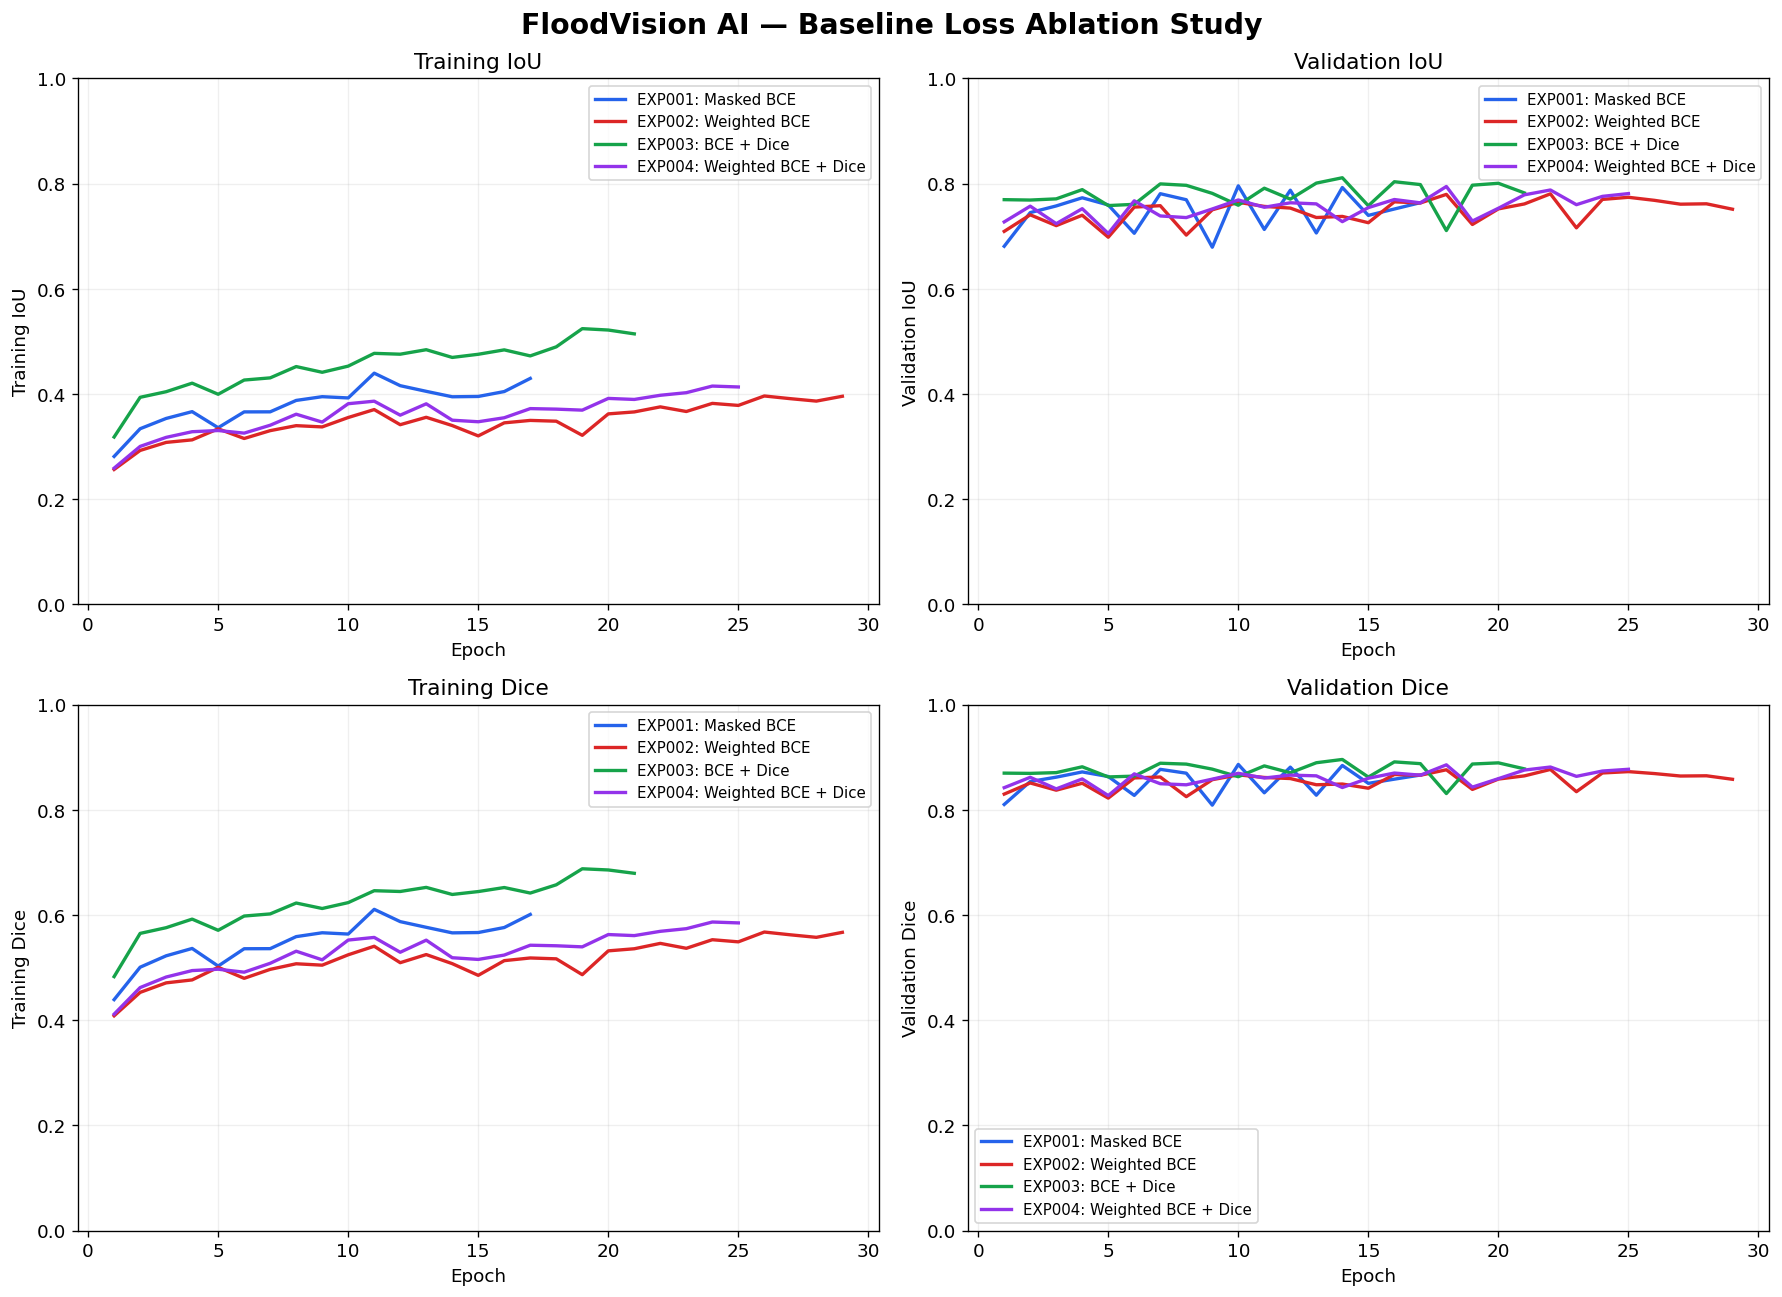

In [30]:
import matplotlib.pyplot as plt

colors = {
    "EXP001": "#2563EB",
    "EXP002": "#DC2626",
    "EXP003": "#16A34A",
    "EXP004": "#9333EA"
}

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "figure.dpi": 120
})

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

plot_metrics = [
    ("train_iou", "Training IoU"),
    ("val_iou", "Validation IoU"),
    ("train_dice", "Training Dice"),
    ("val_dice", "Validation Dice")
]

for ax, (metric, title) in zip(
    axes.flatten(), plot_metrics
):
    for exp_id, df in histories.items():

        label = (
            f"{exp_id}: "
            f"{experiment_runs[exp_id]['loss']}"
        )

        ax.plot(
            df["epoch"],
            df[metric],
            label=label,
            color=colors[exp_id],
            linewidth=2
        )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.2)
    ax.legend()

fig.suptitle(
    "FloodVision AI — Baseline Loss Ablation Study",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "baseline_learning_curves.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIGURES_DIR / "baseline_learning_curves.pdf",
    bbox_inches="tight"
)

plt.show()

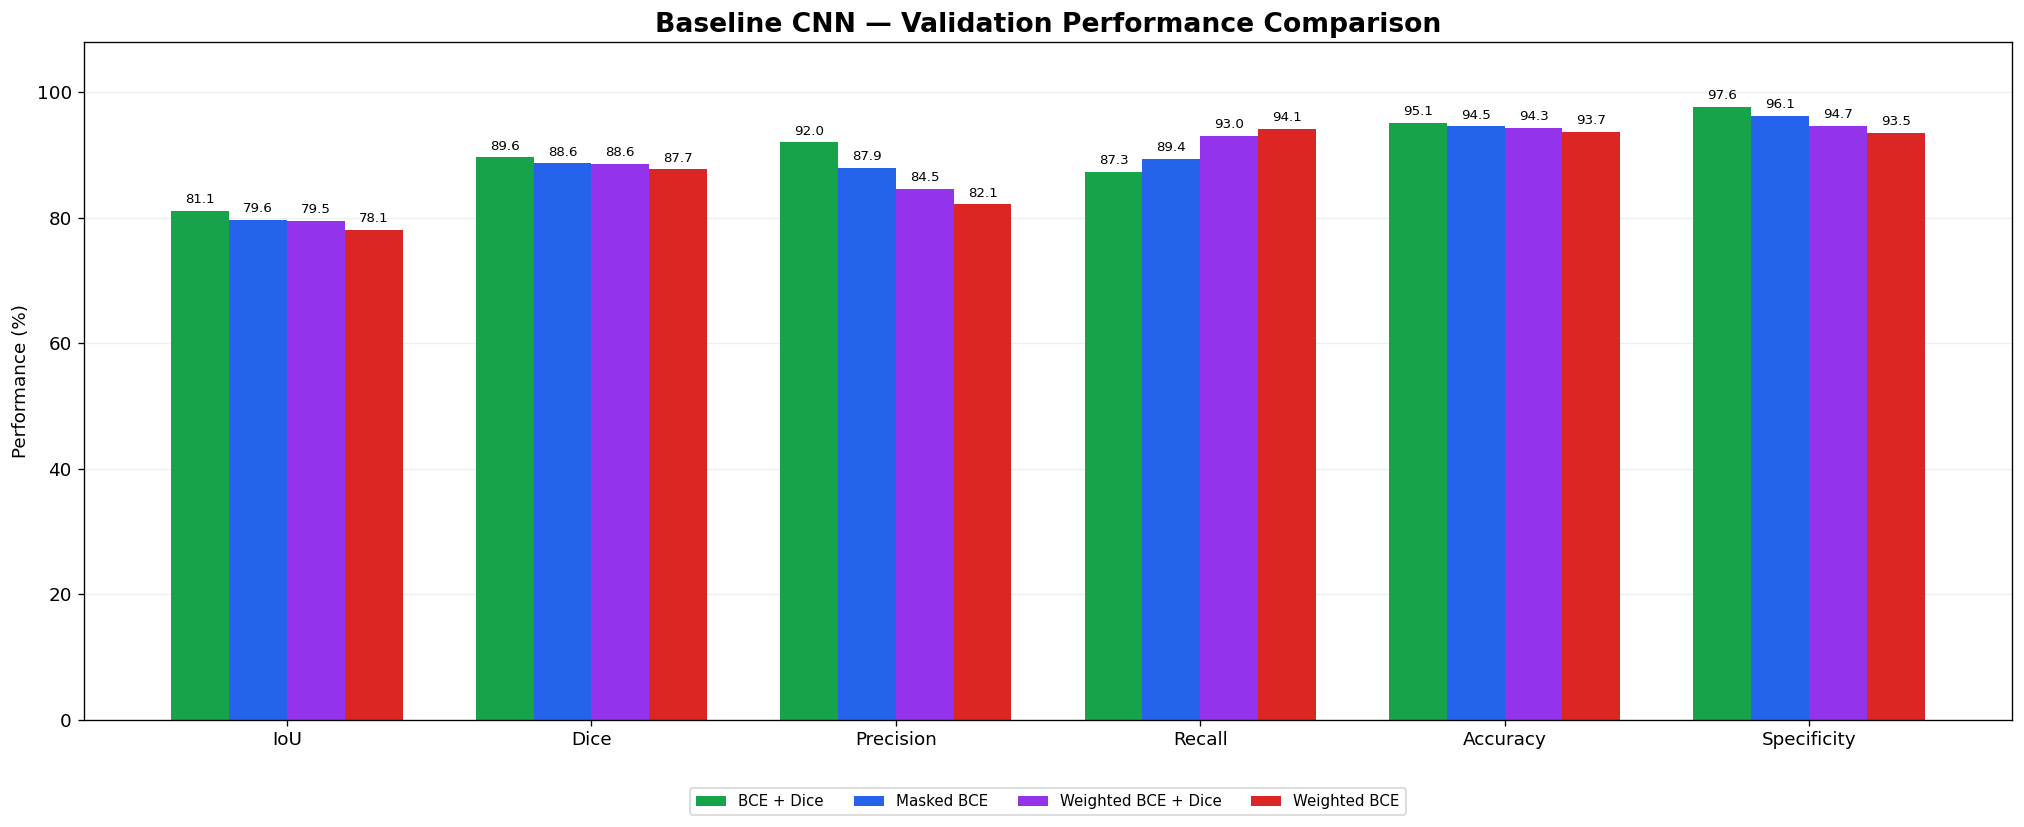

In [31]:
import numpy as np

metrics = [
    "val_iou",
    "val_dice",
    "val_precision",
    "val_recall",
    "val_accuracy",
    "val_specificity"
]

metric_labels = [
    "IoU",
    "Dice",
    "Precision",
    "Recall",
    "Accuracy",
    "Specificity"
]

x = np.arange(len(metrics))
width = 0.19

fig, ax = plt.subplots(figsize=(17, 7))

for i, (_, row) in enumerate(
    summary_df.iterrows()
):
    exp_id = row["experiment"]

    values = row[metrics].astype(float).values * 100

    bars = ax.bar(
        x + (i - 1.5) * width,
        values,
        width,
        label=row["loss_function"],
        color=colors[exp_id]
    )

    ax.bar_label(
        bars,
        fmt="%.1f",
        fontsize=8,
        padding=3
    )

ax.set_xticks(x)
ax.set_xticklabels(metric_labels)
ax.set_ylabel("Performance (%)")
ax.set_ylim(0, 108)

ax.set_title(
    "Baseline CNN — Validation Performance Comparison",
    fontsize=16,
    fontweight="bold"
)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.09),
    ncol=4
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "baseline_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIGURES_DIR / "baseline_performance_comparison.pdf",
    bbox_inches="tight"
)

plt.show()

In [33]:
import zipfile

PROJECT_ROOT = Path(
    "/kaggle/working/FloodVision-AI"
)

BACKUP_PATH = Path(
    "/kaggle/working/FloodVision_Baseline_Experiments.zip"
)

with zipfile.ZipFile(
    BACKUP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for exp_id, info in experiment_runs.items():

        run_dir = EXPERIMENTS_DIR / info["folder"]

        for file in run_dir.rglob("*"):
            if file.is_file():
                archive.write(
                    file,
                    file.relative_to(PROJECT_ROOT)
                )

    for directory in [RESULTS_DIR, FIGURES_DIR]:

        for file in directory.rglob("*"):
            if file.is_file():
                archive.write(
                    file,
                    file.relative_to(PROJECT_ROOT)
                )

with zipfile.ZipFile(BACKUP_PATH, "r") as archive:
    assert archive.testzip() is None
    print("Archived files:", len(archive.namelist()))

print("Backup created successfully!")
print("Path:", BACKUP_PATH)
print(
    "Size:",
    round(BACKUP_PATH.stat().st_size / 1024**2, 2),
    "MB"
)

Archived files: 21
Backup created successfully!
Path: /kaggle/working/FloodVision_Baseline_Experiments.zip
Size: 37.55 MB


In [35]:
import torch
import pandas as pd

from floodvision.datasets.flood_dataset import FloodDataset

distribution_records = []

for split in ["train", "val"]:

    dataset = FloodDataset(
        dataset_config_path="configs/dataset.yaml",
        preprocessing_config_path="configs/preprocessing.yaml",
        split_path=f"data/splits/geographical/{split}.csv",
        transforms=None
    )

    water = 0
    non_water = 0
    invalid = 0

    for sample in dataset:

        mask = sample["mask"]

        water += (mask == 1).sum().item()
        non_water += (mask == 0).sum().item()
        invalid += (mask == -1).sum().item()

    valid = water + non_water

    distribution_records.append({
        "split": split,
        "samples": len(dataset),
        "water_pixels": water,
        "non_water_pixels": non_water,
        "invalid_pixels": invalid,
        "water_percentage": 100 * water / valid,
        "non_water_percentage": 100 * non_water / valid,
        "invalid_percentage": 100 * invalid / (valid + invalid)
    })

distribution_df = pd.DataFrame(distribution_records)

display(distribution_df.round(4))

distribution_df.to_csv(
    RESULTS_DIR / "split_class_distribution.csv",
    index=False
)

,split,samples,water_pixels,non_water_pixels,invalid_pixels,water_percentage,non_water_percentage,invalid_percentage
0,train,340,6557923,70009779,12561258,8.5649,91.4351,14.0934
1,val,48,2667263,8483175,1432474,23.9207,76.0793,11.3843


In [36]:
import torch

from floodvision.models.factory import build_model
from floodvision.losses.factory import build_loss
from floodvision.utils.config import load_config

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

best_run_dir = (
    EXPERIMENTS_DIR /
    experiment_runs["EXP003"]["folder"]
)

config = load_config(
    best_run_dir / "config.yaml"
)

model = build_model(config["model"]).to(device)

checkpoint = torch.load(
    best_run_dir / "checkpoints/best.pt",
    map_location=device,
    weights_only=True
)

print("Checkpoint keys:")
print(checkpoint.keys())

print("\nCheckpoint epoch:", checkpoint["epoch"])
print("Best score:", checkpoint["best_score"])

Checkpoint keys:
dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'best_score', 'config'])

Checkpoint epoch: 14
Best score: 0.811152069591411


In [37]:
model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

criterion = build_loss(
    config["loss"]
).to(device)

print("Best baseline model restored!")
print("Device:", device)
print("Training mode:", model.training)

Best baseline model restored!
Device: cuda
Training mode: False


In [38]:
from torch.utils.data import DataLoader
from floodvision.training.engine import validate_one_epoch

audit_records = []

for split in ["train", "val"]:

    dataset = FloodDataset(
        dataset_config_path="configs/dataset.yaml",
        preprocessing_config_path="configs/preprocessing.yaml",
        split_path=f"data/splits/geographical/{split}.csv",
        transforms=None
    )

    loader = DataLoader(
        dataset,
        batch_size=4,
        shuffle=False,
        num_workers=0,
        pin_memory=(device.type == "cuda")
    )

    print(f"\nEvaluating {split} dataset...")

    metrics = validate_one_epoch(
        model=model,
        dataloader=loader,
        criterion=criterion,
        device=device,
        threshold=0.5
    )

    audit_records.append({
        "split": split,
        "samples": len(dataset),
        **metrics
    })

audit_df = pd.DataFrame(audit_records)

display(audit_df.round(4))

audit_df.to_csv(
    RESULTS_DIR / "baseline_checkpoint_audit.csv",
    index=False
)


Evaluating train dataset...


Validation:   0%|          | 0/85 [00:00<?, ?it/s]


Evaluating val dataset...


Validation:   0%|          | 0/12 [00:00<?, ?it/s]

,split,samples,accuracy,precision,recall,iou,dice,specificity,loss
0,train,340,0.9415,0.6362,0.7407,0.5203,0.6845,0.9603,0.3317
1,val,48,0.9514,0.9196,0.8731,0.8112,0.8957,0.9760,0.2119


In [39]:
import torch
import pandas as pd

confusion_records = []

model.eval()

for split in ["train", "val"]:

    dataset = FloodDataset(
        dataset_config_path="configs/dataset.yaml",
        preprocessing_config_path="configs/preprocessing.yaml",
        split_path=f"data/splits/geographical/{split}.csv",
        transforms=None
    )

    loader = DataLoader(
        dataset,
        batch_size=4,
        shuffle=False,
        num_workers=0,
        pin_memory=(device.type == "cuda")
    )

    tp = tn = fp = fn = 0
    invalid_pixels = 0

    with torch.inference_mode():

        for batch in loader:

            images = batch["image"].to(device)
            masks = batch["mask"].to(device)

            logits = model(images)
            predictions = torch.sigmoid(logits) >= 0.5

            valid = (masks == 0) | (masks == 1)

            invalid_pixels += (~valid).sum().item()

            tp += (predictions & (masks == 1) & valid).sum().item()
            tn += (~predictions & (masks == 0) & valid).sum().item()
            fp += (predictions & (masks == 0) & valid).sum().item()
            fn += (~predictions & (masks == 1) & valid).sum().item()

    confusion_records.append({
        "split": split,
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "valid_pixels": tp + tn + fp + fn,
        "invalid_pixels": invalid_pixels
    })

confusion_df = pd.DataFrame(confusion_records)

display(confusion_df)

confusion_df.to_csv(
    RESULTS_DIR / "baseline_confusion_matrix.csv",
    index=False
)

,split,TP,TN,FP,FN,valid_pixels,invalid_pixels
0,train,4857561,67232176,2777603,1700362,76567702,12561258
1,val,2328760,8279509,203666,338503,11150438,1432474


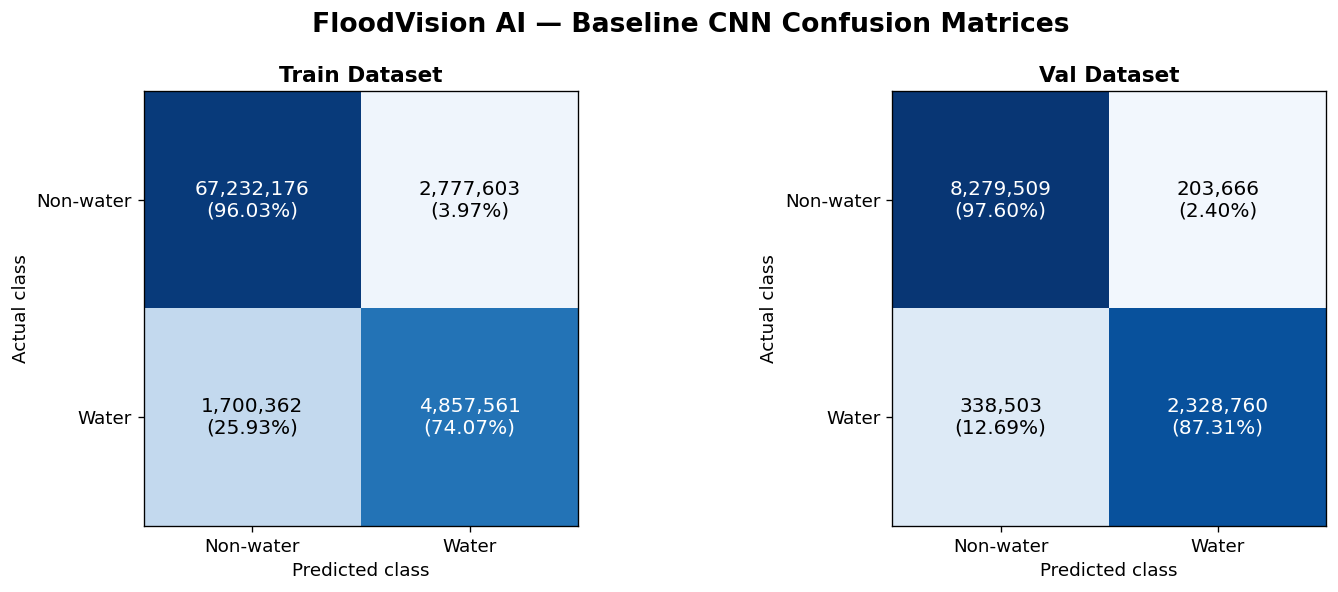

In [40]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (_, row) in zip(
    axes, confusion_df.iterrows()
):
    matrix = np.array([
        [row["TN"], row["FP"]],
        [row["FN"], row["TP"]]
    ], dtype=np.int64)

    normalized = (
        matrix / matrix.sum(axis=1, keepdims=True)
    ) * 100

    im = ax.imshow(
        normalized,
        cmap="Blues",
        vmin=0,
        vmax=100
    )

    for i in range(2):
        for j in range(2):

            ax.text(
                j, i,
                f"{matrix[i, j]:,}\n"
                f"({normalized[i, j]:.2f}%)",
                ha="center",
                va="center",
                fontsize=12,
                color="white"
                if normalized[i, j] > 50
                else "black"
            )

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xticklabels(["Non-water", "Water"])
    ax.set_yticklabels(["Non-water", "Water"])

    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")

    ax.set_title(
        f"{row['split'].capitalize()} Dataset",
        fontweight="bold"
    )

fig.suptitle(
    "FloodVision AI — Baseline CNN Confusion Matrices",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "baseline_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIGURES_DIR / "baseline_confusion_matrices.pdf",
    bbox_inches="tight"
)

plt.show()

In [41]:
from IPython.display import FileLink

FileLink(
    "/kaggle/working/FloodVision_Baseline_Experiments.zip"
)

/kaggle/working/FloodVision_Baseline_Experiments.zip